# ViTPose quality validation (before LSTM training)

Run this only after keypoint extraction has completed. It inspects stored keypoints and samples videos across action classes. It does **not** retrain ViTPose.

In [1]:
# Pose-quality audit: sample videos and visualize stored keypoints
# Run after 02_extract_keypoints_full_dataset.ipynb has completed.

from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import random
import re

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
KEYPOINT_DIR = PROJECT_DIR / "data" / "processed" / "keypoints"
MANIFEST_PATH = PROJECT_DIR / "data" / "processed" / "manifest.csv"
REPORT_PATH = PROJECT_DIR / "data" / "processed" / "extraction_report.csv"

manifest = pd.read_csv(MANIFEST_PATH)
report = pd.read_csv(REPORT_PATH) if REPORT_PATH.exists() else pd.DataFrame()

print("Manifest rows:", len(manifest))
print("Manifest classes:", manifest["label"].nunique())
print("Saved .npz files:", len(list(KEYPOINT_DIR.glob("*.npz"))))


Manifest rows: 13320
Manifest classes: 101
Saved .npz files: 13319


## 1. Match extracted files to manifest videos

The extraction notebook may use either legacy or hashed output filenames, so match each `.npz` using its stored `video_path` when possible.

In [2]:
# Build a mapping from original video path to its saved keypoint file.
# This scans metadata only; it does not load all keypoint arrays into RAM.
npz_by_video = {}
unmatched_npz = []

for npz_path in KEYPOINT_DIR.glob("*.npz"):
    try:
        with np.load(npz_path, allow_pickle=False) as z:
            if "video_path" not in z.files:
                unmatched_npz.append(npz_path)
                continue
            video_path = str(z["video_path"].item())
            npz_by_video[str(Path(video_path).resolve()).lower()] = npz_path
    except Exception as e:
        print("Unreadable NPZ:", npz_path.name, repr(e))

manifest["resolved_key"] = manifest["video_path"].astype(str).map(
    lambda x: str(Path(x).resolve()).lower()
)
manifest["npz_path"] = manifest["resolved_key"].map(npz_by_video)
available = manifest[manifest["npz_path"].notna()].copy()

print("Manifest videos with saved keypoints:", len(available))
print("Classes represented in saved files:", available["label"].nunique())
print("Classes in manifest:", manifest["label"].nunique())

class_counts = available.groupby("label").size().sort_values(ascending=False)
display(class_counts.head(15))


Manifest videos with saved keypoints: 13319
Classes represented in saved files: 101
Classes in manifest: 101


label
CricketShot          167
TennisSwing          166
PlayingDhol          164
HorseRiding          164
PlayingCello         164
BoxingPunchingBag    163
Drumming             161
ShavingBeard         161
Punch                160
BenchPress           160
PlayingGuitar        160
IceDancing           158
PlayingSitar         157
BandMarching         155
Bowling              155
dtype: int64

## 2. Select 12 videos across 6 classes

This picks six classes with extracted videos, then selects up to two videos per class. It is a quick audit sample, not a training subset.

In [3]:
rng = np.random.default_rng(42)
labels_available = sorted(available["label"].dropna().astype(str).unique())

# Prefer classes with at least two extracted videos, if available.
eligible = [
    label for label in labels_available
    if (available["label"].astype(str) == label).sum() >= 2
]
pool = eligible if len(eligible) >= 6 else labels_available
n_classes = min(6, len(pool))
chosen_classes = sorted(rng.choice(pool, size=n_classes, replace=False).tolist())

sample_rows = []
for label in chosen_classes:
    group = available[available["label"].astype(str) == label]
    n_take = min(2, len(group))
    chosen_idx = rng.choice(group.index.to_numpy(), size=n_take, replace=False)
    sample_rows.append(available.loc[chosen_idx])

audit_sample = pd.concat(sample_rows).reset_index(drop=True)
print("Selected classes:", chosen_classes)
print("Selected videos:", len(audit_sample))
display(audit_sample[["label", "video_path", "npz_path"]])


Selected classes: ['BasketballDunk', 'IceDancing', 'PlayingSitar', 'Rowing', 'SumoWrestling', 'WritingOnBoard']
Selected videos: 12


,label,video_path,npz_path
0,BasketballDunk,C:\Users\admin\ViTPose_Action_Recognition\data...,C:\Users\admin\ViTPose_Action_Recognition\data...
1,BasketballDunk,C:\Users\admin\ViTPose_Action_Recognition\data...,C:\Users\admin\ViTPose_Action_Recognition\data...
2,IceDancing,C:\Users\admin\ViTPose_Action_Recognition\data...,C:\Users\admin\ViTPose_Action_Recognition\data...
3,IceDancing,C:\Users\admin\ViTPose_Action_Recognition\data...,C:\Users\admin\ViTPose_Action_Recognition\data...
4,PlayingSitar,C:\Users\admin\ViTPose_Action_Recognition\data...,C:\Users\admin\ViTPose_Action_Recognition\data...
5,PlayingSitar,C:\Users\admin\ViTPose_Action_Recognition\data...,C:\Users\admin\ViTPose_Action_Recognition\data...
6,Rowing,C:\Users\admin\ViTPose_Action_Recognition\data...,C:\Users\admin\ViTPose_Action_Recognition\data...
7,Rowing,C:\Users\admin\ViTPose_Action_Recognition\data...,C:\Users\admin\ViTPose_Action_Recognition\data...
8,SumoWrestling,C:\Users\admin\ViTPose_Action_Recognition\data...,C:\Users\admin\ViTPose_Action_Recognition\data...
9,SumoWrestling,C:\Users\admin\ViTPose_Action_Recognition\data...,C:\Users\admin\ViTPose_Action_Recognition\data...


## 3. Score confidence and missingness

These are **diagnostic indicators**, not a definitive pose-accuracy metric. Confidence values are model heatmap peaks and should not automatically be interpreted as calibrated probabilities.

In [4]:
quality_rows = []
for _, row in audit_sample.iterrows():
    with np.load(row["npz_path"], allow_pickle=False) as z:
        kps = z["keypoints"].astype(np.float32)  # (T,17,3)
        frames = z["frame_indices"] if "frame_indices" in z.files else np.arange(len(kps))
    xy = kps[..., :2]
    conf = kps[..., 2]
    finite_xy = np.isfinite(xy).all(axis=-1)
    valid_conf = np.isfinite(conf)
    # Coordinates may be NaN for missing people/joints; confidence threshold is a rough flag.
    detected = finite_xy & valid_conf & (conf > 0.1)
    quality_rows.append({
        "label": row["label"],
        "video": Path(str(row["video_path"])).name,
        "frames_saved": len(kps),
        "fraction_finite_xy": round(float(finite_xy.mean()), 3),
        "fraction_joints_conf_gt_0.1": round(float(detected.mean()), 3),
        "median_frame_joint_fraction_gt_0.1": round(float(np.median(detected.mean(axis=1))), 3),
        "median_peak_score": round(float(np.nanmedian(conf)), 3),
    })

quality_df = pd.DataFrame(quality_rows)
display(quality_df)


,label,video,frames_saved,fraction_finite_xy,fraction_joints_conf_gt_0.1,median_frame_joint_fraction_gt_0.1,median_peak_score
0,BasketballDunk,v_BasketballDunk_g24_c05.avi,84,1.000,0.936,0.971,0.533
1,BasketballDunk,v_BasketballDunk_g18_c04.avi,26,1.000,0.968,1.000,0.617
2,IceDancing,v_IceDancing_g19_c04.avi,77,0.974,0.969,1.000,0.810
3,IceDancing,v_IceDancing_g21_c02.avi,123,1.000,0.996,1.000,0.866
4,PlayingSitar,v_PlayingSitar_g21_c06.avi,184,0.978,0.978,1.000,0.928
5,PlayingSitar,v_PlayingSitar_g04_c03.avi,211,0.972,0.953,1.000,0.690
6,Rowing,v_Rowing_g10_c05.avi,220,1.000,0.957,0.971,0.821
7,Rowing,v_Rowing_g13_c03.avi,58,1.000,0.919,0.941,0.747
8,SumoWrestling,v_SumoWrestling_g23_c03.avi,125,1.000,0.902,0.941,0.413
9,SumoWrestling,v_SumoWrestling_g19_c04.avi,100,1.000,0.888,0.941,0.405


## 4. Draw saved skeletons over the original frames

This uses the saved original-frame coordinates. If the lines do not line up with the person, that points to a pose/inference/coordinate issue. COCO-17 joint order and connections below must match the training annotation order.

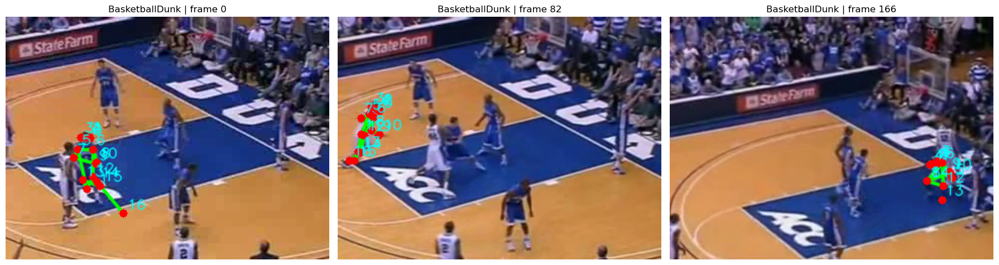

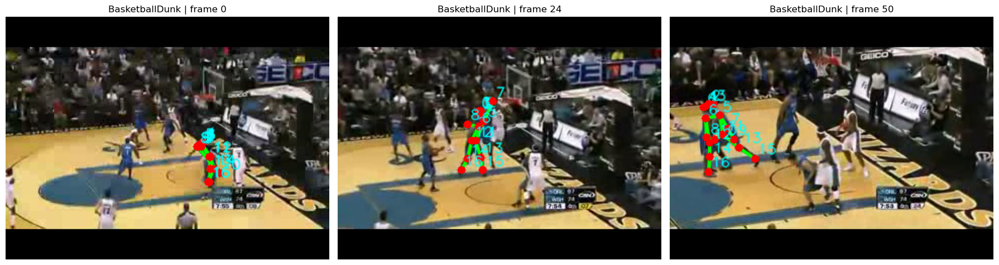

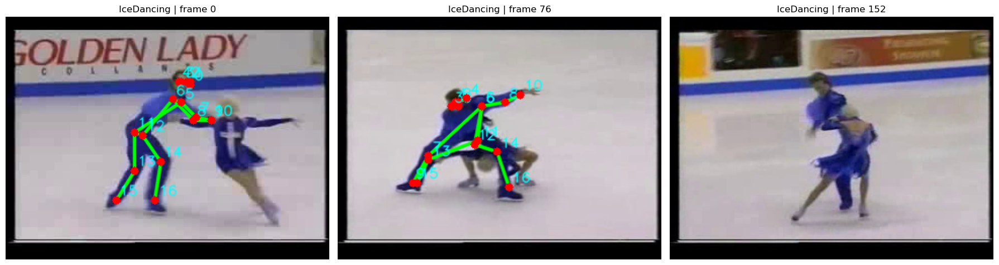

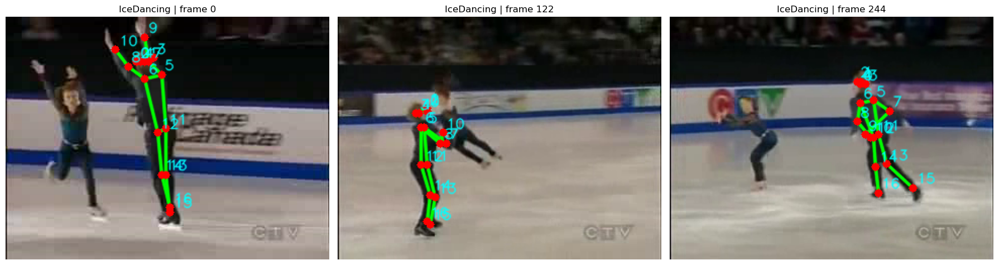

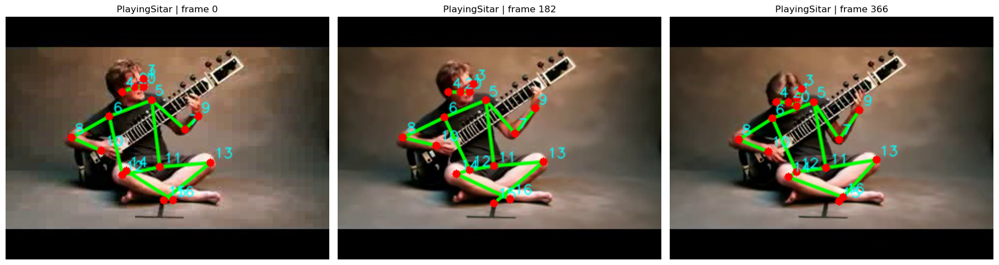

...

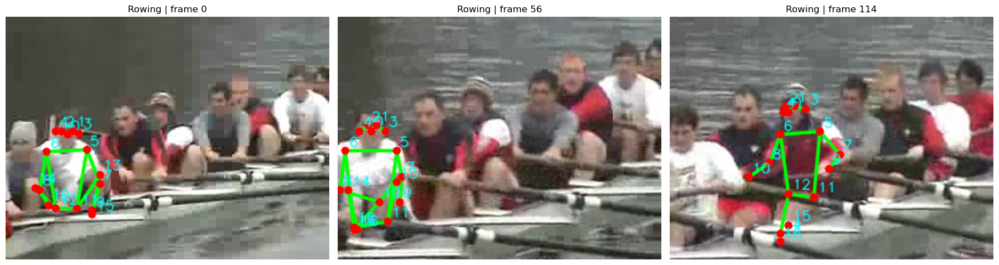

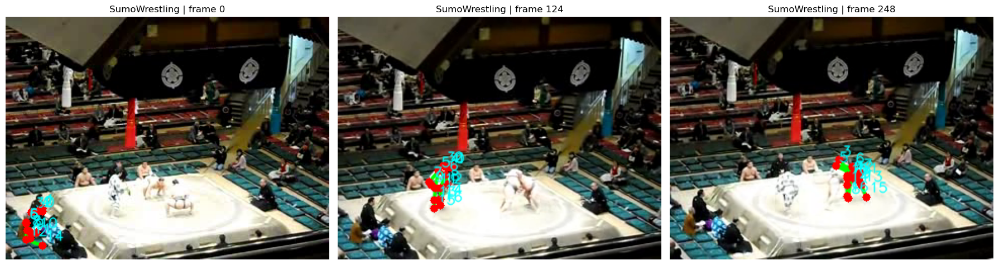

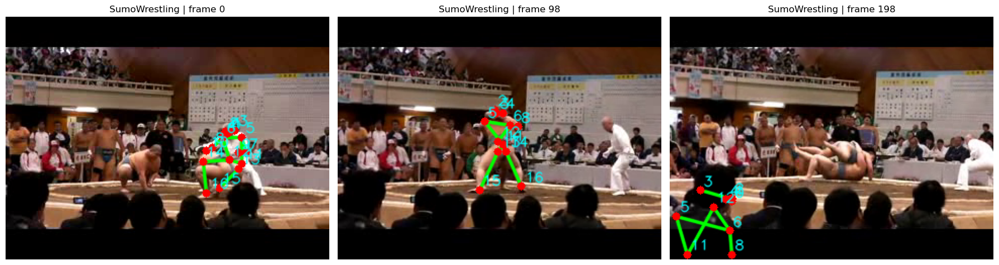

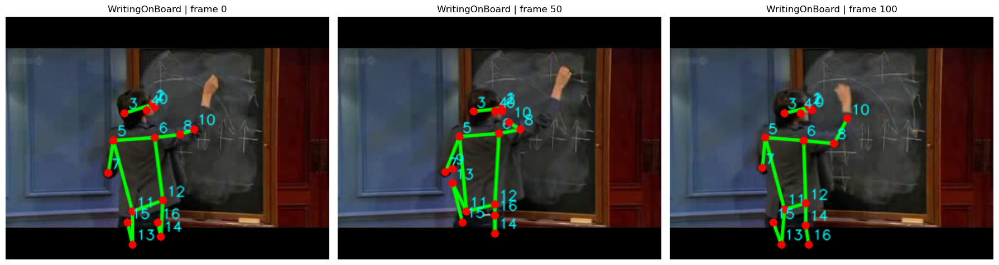

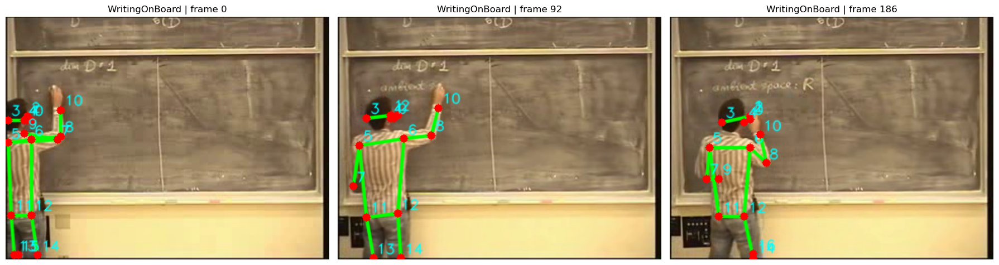

In [5]:
JOINT_NAMES = [
    "nose","left_eye","right_eye","left_ear","right_ear",
    "left_shoulder","right_shoulder","left_elbow","right_elbow",
    "left_wrist","right_wrist","left_hip","right_hip",
    "left_knee","right_knee","left_ankle","right_ankle"
]
SKELETON = [
    (0,1),(0,2),(1,3),(2,4),
    (5,6),(5,7),(7,9),(6,8),(8,10),
    (5,11),(6,12),(11,12),
    (11,13),(13,15),(12,14),(14,16)
]

def draw_pose(frame_bgr, kps, threshold=0.1):
    img = frame_bgr.copy()
    h, w = img.shape[:2]
    for a, b in SKELETON:
        if (np.isfinite(kps[[a,b], :]).all()
                and kps[a,2] > threshold and kps[b,2] > threshold):
            p1 = (int(round(kps[a,0])), int(round(kps[a,1])))
            p2 = (int(round(kps[b,0])), int(round(kps[b,1])))
            if all(0 <= p[0] < w and 0 <= p[1] < h for p in (p1,p2)):
                cv2.line(img, p1, p2, (0,255,0), 2, cv2.LINE_AA)
    for j, (x,y,score) in enumerate(kps):
        if np.isfinite([x,y,score]).all() and score > threshold:
            if 0 <= x < w and 0 <= y < h:
                cv2.circle(img, (int(round(x)), int(round(y))), 4, (0,0,255), -1)
                cv2.putText(img, str(j), (int(x)+4, int(y)-4),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255,255,0), 1, cv2.LINE_AA)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Show 3 evenly spaced saved poses per sampled video (up to 36 images).
MAX_FRAMES_PER_VIDEO = 3
for _, row in audit_sample.iterrows():
    video_path = Path(str(row["video_path"]))
    npz_path = Path(str(row["npz_path"]))
    with np.load(npz_path, allow_pickle=False) as z:
        kps = z["keypoints"].astype(np.float32)
        frame_indices = z["frame_indices"].astype(int)
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        print("Could not open video:", video_path)
        continue

    positions = np.unique(np.linspace(0, len(kps)-1, min(MAX_FRAMES_PER_VIDEO, len(kps))).astype(int))
    fig, axes = plt.subplots(1, len(positions), figsize=(6*len(positions), 5))
    if len(positions) == 1:
        axes = [axes]
    for ax, pos in zip(axes, positions):
        # frame_indices are original video frame indices; seek to that frame.
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_indices[pos]))
        ok, frame = cap.read()
        if not ok:
            ax.set_title(f"Could not read frame {frame_indices[pos]}")
            ax.axis("off")
            continue
        ax.imshow(draw_pose(frame, kps[pos], threshold=0.1))
        ax.set_title(f"{row['label']} | frame {frame_indices[pos]}")
        ax.axis("off")
    cap.release()
    plt.tight_layout()
    plt.show()
